# 04.1 · Train, validation, test: why you must hide data from yourself

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/04-trustworthy-models/01-train-validation-test/lesson.ipynb)

Read the [README](README.md) first. This notebook shows, on ShopWave's real customers:

1. how a model scored on its own training rows lies,
2. why a stratified split matters on small data,
3. how much a test score wobbles by luck, and how the standard error predicts it,
4. how a validation set lets you tune without touching the test set,
5. the time-based split: the only one that rehearses what happens when the model goes live.

## 1. Load the churn table

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail()                                   # ~1 s after the first run
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

def customer_table(cutoff, months=3):
    """One row per customer: features from before `cutoff`, churned = no order in the next `months`."""
    cutoff = pd.Timestamp(cutoff)
    past = sales[sales["InvoiceDate"] < cutoff]
    future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < cutoff + pd.DateOffset(months=months))]
    c = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                        products=("StockCode", "nunique"), country=("Country", "first"),
                                        first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
    c["tenure_days"] = (cutoff - c["first_order"]).dt.days
    c["days_since_last"] = (cutoff - c["last_order"]).dt.days
    came_back = future.groupby("Customer ID")["Revenue"].sum().reindex(c.index).fillna(0) > 0
    c["churned"] = (~came_back).astype(int)
    return c.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
cust = customer_table("2011-09-01")
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}")

3,317 customers, churn rate 43.6%


## 2. Marking your own homework

Fit a decision tree with no depth limit on **all** customers, then score it on the **same** customers.

In [2]:
from sklearn.tree import DecisionTreeClassifier

homework = DecisionTreeClassifier(random_state=0).fit(cust[features], cust["churned"])
print(f"score on the rows it learned from: {homework.score(cust[features], cust['churned']):.1%}")

score on the rows it learned from: 100.0%


Close to perfect. Now do it honestly: hide a quarter of the customers, train on the rest, and score on the hidden quarter.

In [3]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"train {len(X_train):,} / test {len(X_test):,}")

honest = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
print(f"train accuracy: {honest.score(X_train, y_train):.1%}")
print(f"test accuracy:  {honest.score(X_test, y_test):.1%}")
print(f"baseline (always predict 'stays'): {1 - y_test.mean():.1%}")

train 2,487 / test 830
train accuracy: 100.0%
test accuracy:  59.9%
baseline (always predict 'stays'): 56.4%


The same model, the same data. The first number measures **memory**; the second measures **prediction**. Only the second tells retention what to expect next quarter.

## 3. Stratified splits: by hand on 20 customers

The small table has 9 churners and 11 stayers. A 25% test set is 5 customers.

In [4]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

small = pd.read_csv(data_path("shopwave_customers_small.csv"))
print(small["churned"].value_counts().to_dict())
small[["customer_id", "visits_last_month", "days_since_last", "churned"]].head()

{0: 11, 1: 9}


,customer_id,visits_last_month,days_since_last,churned
0,C001,2,55,1
1,C002,11,44,0
2,C003,10,22,0
3,C004,7,58,1
4,C005,7,25,1


In [5]:
from math import comb
p_zero = comb(11, 5) / comb(20, 5)
print(f"P(random test set of 5 contains no churner) = {comb(11, 5)} / {comb(20, 5)} = {p_zero:.3f}")

for seed in range(200):
    _, te = train_test_split(small, test_size=5, random_state=seed)
    if te["churned"].sum() == 0:
        print(f"random_state={seed}: test churners = {te['churned'].tolist()}  ← you cannot measure recall at all")
        break

P(random test set of 5 contains no churner) = 462 / 15504 = 0.030
random_state=35: test churners = [0, 0, 0, 0, 0]  ← you cannot measure recall at all


In [6]:
_, te = train_test_split(small, test_size=5, random_state=seed, stratify=small["churned"])
print("stratified, same seed: test churned =", te["churned"].tolist())

stratified, same seed: test churned = [0, 0, 1, 0, 1]


`stratify=y` keeps the class proportions the same in train and test: 9 × 5/20 = 2.25, rounded to 2 churners in a 5-customer test set. On thousands of rows random splits are close to stratified anyway, but stratifying costs nothing, so do it for classification.

## 4. How much does the test score wobble?

Same model, same data, 20 different random splits. Only the *luck of which customers land in the test set* changes.

In [7]:
from sklearn.tree import DecisionTreeClassifier

def test_score(seed, test_size):
    Xa, Xb, ya, yb = train_test_split(cust[features], cust["churned"], test_size=test_size, random_state=seed)
    return DecisionTreeClassifier(max_depth=4, random_state=0).fit(Xa, ya).score(Xb, yb)

big = np.array([test_score(s, 0.25) for s in range(20)])    # 830 test customers
tiny = np.array([test_score(s, 100) for s in range(20)])    # 100 test customers
print(f"test set of 830: accuracy from {big.min():.1%} to {big.max():.1%}  (mean {big.mean():.1%})")
print(f"test set of 100: accuracy from {tiny.min():.1%} to {tiny.max():.1%}  (mean {tiny.mean():.1%})")

test set of 830: accuracy from 63.5% to 69.0%  (mean 66.4%)
test set of 100: accuracy from 61.0% to 73.0%  (mean 66.5%)


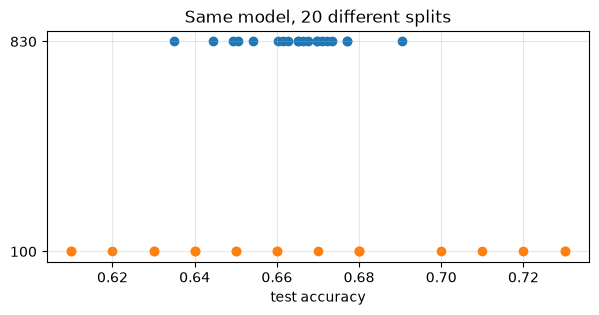

In [8]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.scatter(big, np.zeros(20) + 1, label="830 test customers")
ax.scatter(tiny, np.zeros(20), label="100 test customers")
ax.set(yticks=[0, 1], yticklabels=["100", "830"], xlabel="test accuracy", title="Same model, 20 different splits")
ax.grid(alpha=.3); plt.show()

The **standard error** predicts this wobble before you run anything:

$$SE = \sqrt{\frac{p(1-p)}{n}}$$

In [9]:
for n in [830, 100]:
    p = 0.66
    se = np.sqrt(p * (1 - p) / n)
    print(f"n={n:>4}: SE = sqrt({p}×{1-p:.2f}/{n}) = {se:.4f}  →  95% of scores within ±{2*se:.1%}")

n= 830: SE = sqrt(0.66×0.34/830) = 0.0164  →  95% of scores within ±3.3%
n= 100: SE = sqrt(0.66×0.34/100) = 0.0474  →  95% of scores within ±9.5%


About ±3 points for 830 customers and about ±9 points for 100. Two models whose test scores differ by 1 point on 830 customers are **not** distinguishable. Lesson 04.7 (cross-validation) gives you a cheaper way to see the wobble.

## 5. A validation set for tuning

Choosing `max_depth` is a decision. If you make it by looking at the test score, the test set has helped train the model and its score is no longer an honest exam. So split three ways: 60% train, 20% validation, 20% test.

In [10]:
X_tmp, X_te, y_tmp, y_te = train_test_split(cust[features], cust["churned"], test_size=0.20,
                                            random_state=42, stratify=cust["churned"])
X_tr, X_val, y_tr, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25,   # 0.25 × 80% = 20%
                                            random_state=42, stratify=y_tmp)
print(f"train {len(X_tr):,} / validation {len(X_val):,} / test {len(X_te):,}")

train 1,989 / validation 664 / test 664


In [11]:
rows = []
for depth in range(1, 11):
    m = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X_tr, y_tr)
    rows.append({"max_depth": depth, "train": m.score(X_tr, y_tr),
                 "validation": m.score(X_val, y_val), "test (do not look!)": m.score(X_te, y_te)})
tuning = pd.DataFrame(rows).set_index("max_depth")
tuning.round(3)

,train,validation,test (do not look!)
max_depth,,,
1,0.658,0.666,0.652
2,0.659,0.663,0.649
3,0.686,0.663,0.660
4,0.694,0.654,0.649
5,0.708,0.642,0.648
6,0.734,0.661,0.660
7,0.755,0.651,0.651
8,0.777,0.633,0.640
9,0.814,0.637,0.627


In [12]:
best = tuning["validation"].idxmax()
final = DecisionTreeClassifier(max_depth=best, random_state=0).fit(X_tmp, y_tmp)   # retrain on train+val
print(f"chosen by validation: max_depth={best}")
print(f"test accuracy, looked at ONCE: {final.score(X_te, y_te):.1%}")
print(f"best test score in the table (what a peeker would report): {tuning['test (do not look!)'].max():.1%}")

chosen by validation: max_depth=1
test accuracy, looked at ONCE: 65.8%
best test score in the table (what a peeker would report): 66.0%


The test column is printed only so you can see what peeking would do. In real work you would not compute it until the very end. The honest number is the one you get after choosing on validation and scoring the test set once.

Here the peeker would only gain a fraction of a point, because the test column is fairly flat. But the bias always points the same way, **upwards**, and it grows with every extra setting you try. Try 200 combinations of settings against the test set and the best one will look several points better than it really is.

## 6. The time-based split: rehearsing the future

ShopWave will use the model like this: on 1 September, score every customer, then wait three months to see who came back. A random split mixes customers from the same moment into train and test. A **time-based split** trains on an *earlier* snapshot and tests on a *later* one, exactly like live use.

In [13]:
june = customer_table("2011-06-01")      # features before 1 June, target = no order Jun–Aug
sept = cust                               # features before 1 Sep,  target = no order Sep–Nov
print(f"June snapshot: {len(june):,} customers, churn {june['churned'].mean():.1%}")
print(f"Sept snapshot: {len(sept):,} customers, churn {sept['churned'].mean():.1%}")

June snapshot: 2,718 customers, churn 50.4%
Sept snapshot: 3,317 customers, churn 43.6%


In [14]:
past_model = DecisionTreeClassifier(max_depth=4, random_state=0).fit(june[features], june["churned"])
print(f"trained on June, scored on June (homework): {past_model.score(june[features], june['churned']):.1%}")
print(f"trained on June, scored on September (live rehearsal): {past_model.score(sept[features], sept['churned']):.1%}")

rand = DecisionTreeClassifier(max_depth=4, random_state=0).fit(X_train, y_train)
print(f"random split inside September, for comparison: {rand.score(X_test, y_test):.1%}")

trained on June, scored on June (homework): 70.9%
trained on June, scored on September (live rehearsal): 66.8%
random split inside September, for comparison: 65.1%


Here the time-based score happens to be close to the random-split score: this model travels from June to September reasonably well. That is good news you could not have known without the test. And look at the churn rates: **50% in summer, 44% in autumn**. The world moved between snapshots. A random split can never show you that; a time-based split always will.

## Quiz answers

1. Because the model has already seen those rows. A flexible model can memorise them, so the score measures memory, not prediction (here 100% on its own rows vs 59.9% on hidden ones).
2. The validation set is used repeatedly to choose settings; the test set is used once, at the end, to report the final score.
3. `stratify=y` keeps the class proportions equal in train and test. It matters most when data is small or a class is rare.
4. $SE = \sqrt{0.8 \times 0.2 / 400} = 0.02$, so roughly ±4 points at 95%.
5. A time-based split: train on an earlier snapshot, test on a later one, because that is how the model will be used.

**Next:** [04.2 Data leakage](../02-data-leakage/)